# Comparación de tres modelos de sentimientos en comentarios bancarios

**Caso:** NLP multiclase POS/NEU/NEG. Dataset sintético de 45 registros. Ejecute las celdas en orden. Los resultados se generan al correr el notebook, no se presuponen.

**Preparación:** En Colab, Entorno de ejecución → Cambiar tipo de entorno → GPU T4 (si disponible). Suba `comentarios_bancarios.csv` desde la carpeta `data/` cuando se solicite.


In [1]:
%pip -q install "transformers>=4.44,<5" "datasets>=2.20" "huggingface_hub>=0.25" "accelerate>=0.33" "scikit-learn>=1.4" "pandas>=2.0" "matplotlib>=3.8" psutil

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 68.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, time, gc, json, platform, importlib.metadata
import pandas as pd, numpy as np, torch, matplotlib.pyplot as plt
from transformers import pipeline, AutoConfig
from huggingface_hub import login
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from google.colab import files, userdata
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
!nvidia-smi
os.makedirs('results',exist_ok=True)
print('Transformers:',importlib.metadata.version('transformers'))

GPU: True Tesla T4
Sun Oct 18 23:38:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------------

## Autenticación segura
Los tres modelos son públicos; la autenticación es opcional. Si desea autenticar, guarde el token como secreto `HF_TOKEN` en Colab y habilite el acceso del notebook. **Nunca escriba el token en el código ni en GitHub.**

In [3]:
try:
    token=userdata.get('HF_TOKEN')
    if token: login(token=token,add_to_git_credential=False); print('Hub: autenticado')
    else: print('Hub: modelos públicos, sin autenticación')
except Exception as e:
    print('Hub: acceso público sin autenticación; detalle:',str(e)[:120])

Hub: acceso público sin autenticación; detalle: Secret HF_TOKEN does not exist.


In [4]:
if not os.path.exists('comentarios_bancarios.csv'):
    print('Suba el CSV incluido en data/comentarios_bancarios.csv')
    uploaded=files.upload()
    assert 'comentarios_bancarios.csv' in uploaded, 'Seleccione comentarios_bancarios.csv'
df=pd.read_csv('comentarios_bancarios.csv')
assert {'id','texto','sentimiento','origen'}.issubset(df.columns)
assert df.sentimiento.isin(['POS','NEG','NEU']).all()
assert not df.texto.isna().any()
print(df.sentimiento.value_counts())
display(df.head())

Suba el CSV incluido en data/comentarios_bancarios.csv


Saving comentarios_bancarios.csv to comentarios_bancarios.csv
sentimiento
POS    15
NEG    15
NEU    15
Name: count, dtype: int64


,id,texto,sentimiento,origen
0,B001,La atención fue excelente y resolvieron mi pro...,POS,sintetico_autoria_proyecto
1,B002,La aplicación bancaria es muy fácil de usar.,POS,sintetico_autoria_proyecto
2,B003,Estoy satisfecho con la rapidez de la transfer...,POS,sintetico_autoria_proyecto
3,B004,El asesor explicó claramente las opciones de a...,POS,sintetico_autoria_proyecto
4,B005,Mi tarjeta llegó antes de lo esperado.,POS,sintetico_autoria_proyecto


## Modelos y normalización
El modelo de estrellas convierte 1–2→NEG, 3→NEU, 4–5→POS. La conversión simplifica la escala y puede introducir sesgos. Se comparan los tres sobre exactamente los mismos textos.

In [5]:
MODELS={
 'RoBERTuito':'pysentimiento/robertuito-sentiment-analysis',
 'XLM-RoBERTa':'cardiffnlp/twitter-xlm-roberta-base-sentiment',
 'BERT estrellas':'nlptown/bert-base-multilingual-uncased-sentiment',
}
def normalize(label):
    s=str(label).strip().lower()
    if 'star' in s:
        n=int(s.split()[0]);return 'NEG' if n<=2 else ('NEU' if n==3 else 'POS')
    mapping={'positive':'POS','neutral':'NEU','negative':'NEG','pos':'POS','neu':'NEU','neg':'NEG','label_0':'NEG','label_1':'NEU','label_2':'POS'}
    if s not in mapping: raise ValueError(f'Etiqueta no reconocida: {label}')
    return mapping[s]
texts=df.texto.astype(str).tolist(); y=df.sentimiento.tolist()
metrics=[]; predictions=[]
DEVICE=0 if torch.cuda.is_available() else -1
print('Dispositivo:',DEVICE)

Dispositivo: 0


In [6]:
for name,repo in MODELS.items():
    print('\nEvaluando:',name,repo)
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    start_load=time.perf_counter()
    clf=pipeline('text-classification',model=repo,tokenizer=repo,device=DEVICE, truncation=True)
    load_s=time.perf_counter()-start_load
    params=sum(p.numel() for p in clf.model.parameters())
    # Warm-up fuera de la medición
    _=clf(texts[0],truncation=True,max_length=256)
    if torch.cuda.is_available():torch.cuda.synchronize()
    start=time.perf_counter()
    outputs=clf(texts,batch_size=8,truncation=True,max_length=256)
    if torch.cuda.is_available():torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    pred=[normalize(v['label']) for v in outputs]
    precision,recall,f1,_=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    metrics.append({'modelo':name,'repo':repo,'accuracy':accuracy_score(y,pred),'precision_macro':precision,'recall_macro':recall,'f1_macro':f1,'latencia_total_s':elapsed,'latencia_media_ms':1000*elapsed/len(texts),'carga_s':load_s,'parametros':params,'dispositivo':'GPU' if DEVICE==0 else 'CPU','n':len(texts)})
    for r,o,p in zip(df.to_dict('records'),outputs,pred):predictions.append({'id':r['id'],'modelo':name,'real':r['sentimiento'],'predicho':p,'confianza_top1':o['score'],'texto':r['texto']})
    print(classification_report(y,pred,labels=['NEG','NEU','POS'],zero_division=0))
    del clf;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
results=pd.DataFrame(metrics).sort_values('f1_macro',ascending=False)
display(results)


Evaluando: RoBERTuito pysentimiento/robertuito-sentiment-analysis


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/435M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cuda:0


              precision    recall  f1-score   support

         NEG       0.82      0.93      0.88        15
         NEU       0.50      0.13      0.21        15
         POS       0.58      0.93      0.72        15

    accuracy                           0.67        45
   macro avg       0.64      0.67      0.60        45
weighted avg       0.64      0.67      0.60        45



,modelo,repo,accuracy,precision_macro,recall_macro,f1_macro,latencia_total_s,latencia_media_ms,carga_s,parametros,dispositivo,n
0,RoBERTuito,pysentimiento/robertuito-sentiment-analysis,0.911111,0.929825,0.911111,0.909502,0.158305,3.517893,8.926235,108791043,GPU,45
1,XLM-RoBERTa,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.888889,0.905093,0.888889,0.887460,0.263588,5.857513,33.477708,278045955,GPU,45
2,BERT estrellas,nlptown/bert-base-multilingual-uncased-sentiment,0.666667,0.635621,0.666667,0.601158,0.113689,2.526425,28.369596,167360261,GPU,45


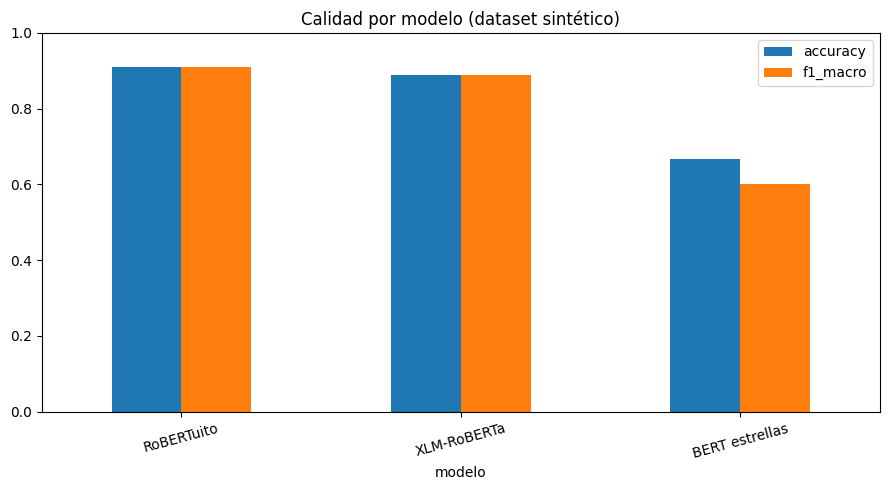

Modelo con mayor F1 macro: RoBERTuito
Modelo con menor latencia: BERT estrellas
Recomendación condicionada: exigir accuracy >=0.80 y F1 macro >=0.75; entre los elegibles, menor latencia.
Recomendado provisional: RoBERTuito


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
results.to_csv('results/metricas_modelos.csv',index=False)
pd.DataFrame(predictions).to_csv('results/predicciones_modelos.csv',index=False)
meta={'python':platform.python_version(),'torch':torch.__version__,'transformers':importlib.metadata.version('transformers'),'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,'dataset_n':len(df),'batch_size':8,'max_length':256,'models':MODELS}
with open('results/entorno.json','w') as f:json.dump(meta,f,indent=2)
ax=results.plot.bar(x='modelo',y=['accuracy','f1_macro'],rot=15,ylim=(0,1),figsize=(9,5),title='Calidad por modelo (dataset sintético)')
plt.tight_layout();plt.savefig('results/comparacion.png',dpi=160);plt.show()
print('Modelo con mayor F1 macro:',results.iloc[0]['modelo'])
print('Modelo con menor latencia:',results.sort_values('latencia_media_ms').iloc[0]['modelo'])
print('Recomendación condicionada: exigir accuracy >=0.80 y F1 macro >=0.75; entre los elegibles, menor latencia.')
eligible=results[(results.accuracy>=0.80)&(results.f1_macro>=0.75)]
print('Recomendado provisional:',eligible.sort_values('latencia_media_ms').iloc[0]['modelo'] if len(eligible) else 'Ninguno cumple: ampliar datos y revisar adaptación')
for f in ['metricas_modelos.csv','predicciones_modelos.csv','entorno.json','comparacion.png']:
    files.download('results/'+f)

## Conclusiones parciales y limitaciones
- Los números solo son válidos tras ejecutar el cuaderno.
- El dataset es **sintético, pequeño y balanceado**: no demuestra rendimiento con clientes reales.
- La confianza top-1 no es accuracy; accuracy y F1 requieren etiquetas de referencia.
- Las latencias dependen del hardware, calentamiento y lote.
- Para producción: ampliar muestras, revisar errores de clase NEG, anonimizar datos reales, comprobar licencias y ejecutar validación externa.
- No se realiza fine-tuning; primero se evalúa inferencia sin reentrenamiento.
